## Premières manipulations de données

Reprise du modèle en rajoutant 4 features faciles à rajouter. Le centre est ajouté plus loin sous forme d'indicateurs binaires.

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split
from sksurv.ensemble import RandomSurvivalForest
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored , concordance_index_ipcw
from sklearn.impute import SimpleImputer
from sksurv.util import Surv

from iscn_authenticator import validate_karyotype

from time import time

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sksurv.metrics import as_concordance_index_ipcw_scorer

from sksurv.ensemble import GradientBoostingSurvivalAnalysis
from sksurv.metrics import concordance_index_ipcw


# Clinical Data
df = pd.read_csv("./clinical_train.csv")
df_test = pd.read_csv("./clinical_test.csv")

# Molecular Data
maf_df = pd.read_csv("./molecular_train.csv", dtype={"CHR": str})
maf_df_test = pd.read_csv("./molecular_test.csv", dtype={"CHR": str})
# Train + test réunis : sert uniquement à calculer des features par patient (aucune cible utilisée)
maf_all = pd.concat([maf_df, maf_df_test], ignore_index=True)


# Target Data
target_df = pd.read_csv("./target_train.csv")

In [60]:
# Drop rows where 'OS_YEARS' is NaN if conversion caused any issues
target_df.dropna(subset=['OS_YEARS', 'OS_STATUS'], inplace=True)

# Check the data types to ensure 'OS_STATUS' is boolean and 'OS_YEARS' is numeric
print(target_df[['OS_STATUS', 'OS_YEARS']].dtypes)

# Contarget_dfvert 'OS_YEARS' to numeric if it isn’t already
target_df['OS_YEARS'] = pd.to_numeric(target_df['OS_YEARS'], errors='coerce')

# Ensure 'OS_STATUS' is boolean
target_df['OS_STATUS'] = target_df['OS_STATUS'].astype(bool)

# Select features
features = ['BM_BLAST', 'WBC', 'ANC', 'HB', 'PLT', 'MONOCYTES']
target = ['OS_YEARS', 'OS_STATUS']

# Create the survival data format
data = df.merge(target_df, on="ID")
X = data[features]
y = Surv.from_dataframe("OS_STATUS", "OS_YEARS", data)

print(X[:10])
y[:10]

OS_STATUS    float64
OS_YEARS     float64
dtype: object
   BM_BLAST    WBC   ANC    HB    PLT  MONOCYTES
0      14.0    2.8   0.2   7.6  119.0       0.70
1       1.0    7.4   2.4  11.6   42.0       0.10
2      15.0    3.7   2.1  14.2   81.0       0.10
3       1.0    3.9   1.9   8.9   77.0       0.10
4       6.0  128.0   9.7  11.1  195.0       0.90
5       3.0   15.8  12.6   8.0  492.0       0.88
6      12.0    6.2   3.0   9.6   61.0       0.80
7      15.0    4.8   1.5   9.4  142.0       0.70
8      14.0    0.8   0.2   8.8   23.0       0.00
9      14.0    1.4   0.2   7.4  183.0       0.00


array([( True, 1.11506849), (False, 4.92876712), (False, 2.04383562),
       ( True, 2.47671233), (False, 3.14520548), ( True, 2.01369863),
       (False, 0.8109589 ), ( True, 1.84931507), ( True, 1.00547945),
       (False, 0.29315068)],
      dtype=[('OS_STATUS', '?'), ('OS_YEARS', '<f8')])

In [61]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [62]:
# Survival-aware imputation for missing values
imputer = SimpleImputer(strategy="median")
X_train[features] = imputer.fit_transform(X_train[features])
X_test[features] = imputer.transform(X_test[features])

Fonctions d'évaluation utilisées à chaque étape de feature engineering : LightGBM (régression sur `OS_YEARS`, ignore la censure) et un Cox légèrement pénalisé (prend en compte la censure).

In [ ]:
import lightgbm as lgb

def eval_lgb(X_tr, X_te):
    params = {'max_depth': 3, 'learning_rate': 0.05, 'verbose': -1}
    lgb_model = lgb.train(params=params, train_set=lgb.Dataset(X_tr, label=y_train['OS_YEARS']))
    ci_tr = concordance_index_ipcw(y_train, y_train, -lgb_model.predict(X_tr), tau=7)[0]
    ci_te = concordance_index_ipcw(y_train, y_test, -lgb_model.predict(X_te), tau=7)[0]
    print(f"LightGBM IPCW C-index  train : {ci_tr:.4f}   test : {ci_te:.4f}")

def eval_cox(X_tr, X_te, alpha=1.0):
    cox = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", CoxPHSurvivalAnalysis(alpha=alpha)),
    ])
    cox.fit(X_tr, y_train)
    ci_tr = concordance_index_ipcw(y_train, y_train, cox.predict(X_tr), tau=7)[0]
    ci_te = concordance_index_ipcw(y_train, y_test, cox.predict(X_te), tau=7)[0]
    print(f"Cox      IPCW C-index  train : {ci_tr:.4f}   test : {ci_te:.4f}")

In [ ]:
# Import necessary libraries
import lightgbm as lgb
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv

# Define LightGBM parameters
lgbm_params = {
    'max_depth': 3,
    'learning_rate': 0.05,
    'verbose': -1
}

# Prepare the data for LightGBM
# Scale the target (OS_YEARS) to reduce skew, apply weights based on event status
X_train_lgb = X_train  # Features for training
y_train_transformed = y_train['OS_YEARS']

# Create LightGBM dataset
train_dataset = lgb.Dataset(X_train_lgb, label=y_train_transformed)

# Train the LightGBM model
model = lgb.train(params=lgbm_params, train_set=train_dataset)

# Make predictions on the training and testing sets
pred_train = -model.predict(X_train)
pred_test = -model.predict(X_test)

# Evaluate the model using Concordance Index IPCW
train_ci_ipcw = concordance_index_ipcw(y_train, y_train, pred_train, tau=7)[0]
test_ci_ipcw = concordance_index_ipcw(y_train, y_test, pred_test, tau=7)[0]
print(f"LightGBM Survival Model Concordance Index IPCW on train: {train_ci_ipcw}")
print(f"LightGBM Survival Model Concordance Index IPCW on test: {test_ci_ipcw}")

eval_cox(X_train, X_test)

Premier gain de 1% sur les données test et les données d'entraînement...

<Figure size 2000x1000 with 0 Axes>

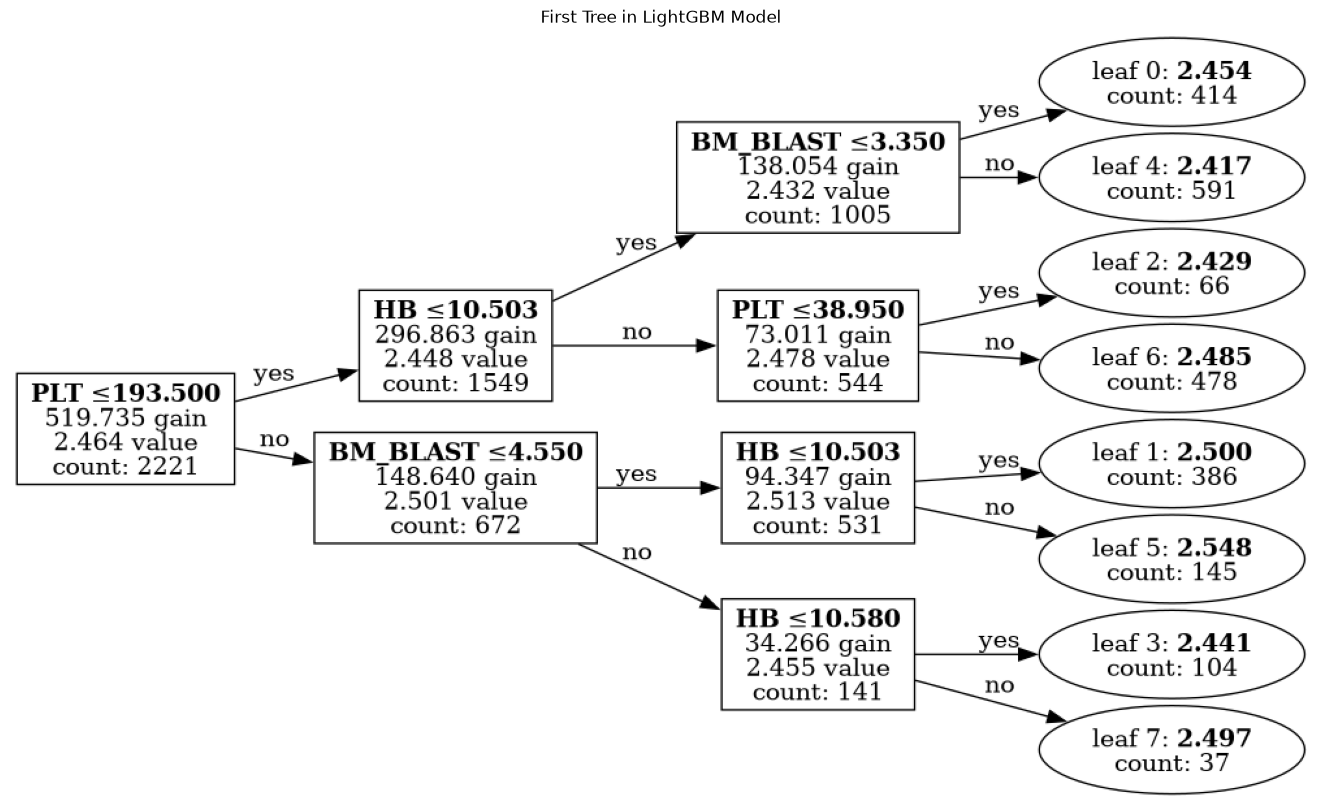

In [64]:
# Assuming the LightGBM model is defined as `model`
plt.figure(figsize=(20, 10))
lgb.plot_tree(model, tree_index=0, figsize=(20, 10), show_info=['split_gain', 'internal_value', 'internal_count', 'leaf_count'])
plt.title("First Tree in LightGBM Model")
plt.show()

## Un peu de feature engineering

l'objectif ici est avant d'appliquer des modèles de commencer par essayer de former un ensemble de données le plus pertinent et complet possible

# Extraction des informations depuis les données moléculaires

On se propose de reprendre le principe du "Step 5" du benchmark en un peu plus sophistiqué. On va essayer de rajouter des features à partir des données EFFECT en comptabilisant uniquement les effets qui ont des conséquences sur la production des protéines : non_synonymous_codon, frameshift_variant, stop_gained, splice_site_variant, inframe_codon_loss, inframe_codon_gain, PTD, ITD et initiator_codon_change. Les autres effets de mutations sont à priori négligeables. L'idée : compter le nombre de mutations de chaque type pour chaque patient en considérant que cette cractéristique est liée au risque de mort par leucémie.

In [ ]:
mutation_effects = [
    'non_synonymous_codon',
    'frameshift_variant',
    'stop_gained',
    'splice_site_variant',
    'inframe_codon_loss',
    'inframe_codon_gain',
    'PTD',
    'ITD',
    'initiator_codon_change',
]
mutation_counts = (
    maf_all.loc[maf_all['EFFECT'].isin(mutation_effects)]
    .groupby(['ID', 'EFFECT'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=mutation_effects, fill_value=0)
)

def add_effect_counts(X_part, ids):
    counts = mutation_counts.reindex(ids, fill_value=0)
    counts.index = X_part.index
    return X_part.join(counts)

X_augmented = add_effect_counts(X, data['ID'].to_numpy())

print(X_augmented[:10])

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_augmented, y, test_size=0.3, random_state=42)


# Survival-aware imputation for missing values
imputer = SimpleImputer(strategy="median")
X_train[features] = imputer.fit_transform(X_train[features])
X_test[features] = imputer.transform(X_test[features])

# Define LightGBM parameters
lgbm_params = {
    'max_depth': 3,
    'learning_rate': 0.05,
    'verbose': -1
}

# Prepare the data for LightGBM
# Scale the target (OS_YEARS) to reduce skew, apply weights based on event status
X_train_lgb = X_train  # Features for training
y_train_transformed = y_train['OS_YEARS']

# Create LightGBM dataset
train_dataset = lgb.Dataset(X_train_lgb, label=y_train_transformed)

# Train the LightGBM model
model = lgb.train(params=lgbm_params, train_set=train_dataset)

# Make predictions on the training and testing sets
pred_train = -model.predict(X_train)
pred_test = -model.predict(X_test)

# Evaluate the model using Concordance Index IPCW
train_ci_ipcw = concordance_index_ipcw(y_train, y_train, pred_train, tau=7)[0]
test_ci_ipcw = concordance_index_ipcw(y_train, y_test, pred_test, tau=7)[0]
print(f"LightGBM Survival Model Concordance Index IPCW on train: {train_ci_ipcw}")
print(f"LightGBM Survival Model Concordance Index IPCW on test: {test_ci_ipcw}")

eval_cox(X_train, X_test)

Encore un gain de 2% pour le train set et 1% pour le test set. Cependant, cette création de feature semble toujours assez naïve puisque l'on récupère uniquement de l'information sur la mesure et la manière dans laquelle le patient a été touché par des mutations toujours sans savoir exactement lesquelles.

Il pourrait être pertinent de trouver un moyen de sélectionner les mutations qui peuvent avoir un lien avec la leucémie. Une première idée pourrait être de prendre les N premières mutations les plus représentées parmi les patients qui sont décédés après leur diagnostique (ici la censure nous empêche peut-être de prendre en compte d'autres mutations). On caractérise une mutation par le 5-uplet (CHR, START, END, REF, ALT).

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_augmented, y, test_size=0.3, random_state=42)


# Survival-aware imputation for missing values
imputer = SimpleImputer(strategy="median")
X_train[features] = imputer.fit_transform(X_train[features])
X_test[features] = imputer.transform(X_test[features])

#nombre de mutations à prendre en compte (peut être modifié pour tester l'optimisation)
N=30

# IDs patients des deux parties du split (les index de X viennent de `data`)
ids_train = data.loc[X_train.index, 'ID'].to_numpy()
ids_test = data.loc[X_test.index, 'ID'].to_numpy()

# 5-uplets (CHR, START, END, REF, ALT) triés par fréquence chez les patients décédés du TRAIN
mutation_columns = ['CHR', 'START', 'END', 'REF', 'ALT']

def count_5tuples(deceased_ids):
    return (
        maf_all.loc[maf_all['ID'].isin(deceased_ids)]
        .dropna(subset=mutation_columns)
        .groupby(mutation_columns)
        .size()
        .sort_values(ascending=False, kind='stable')
    )

mutation_5tuple_counts = count_5tuples(ids_train[y_train['OS_STATUS']])
mutation_5tuples_by_frequency = mutation_5tuple_counts.tolist()

print(f"{len(mutation_5tuples_by_frequency)} 5-uplets distincts")
mutation_5tuples_by_frequency[:30]

In [ ]:
# Score de présence pondéré des N mutations les plus fréquentes
def add_rank_score(X_part, ids, top_counts):
    top = top_counts.reset_index(name='count')
    top['rank_weight'] = top['count'] / top['count'].max()
    scores = (
        maf_all.merge(top[mutation_columns + ['rank_weight']], on=mutation_columns, how='inner')
        .drop_duplicates(subset=['ID'] + mutation_columns)
        .groupby('ID')['rank_weight']
        .sum()
    )
    X_out = X_part.copy()
    X_out['mutation_rank_score'] = pd.Series(ids).map(scores).fillna(0.0).to_numpy()
    return X_out

top_mutations = mutation_5tuple_counts.head(N)
X_train_aug = add_rank_score(X_train, ids_train, top_mutations)
X_test_aug = add_rank_score(X_test, ids_test, top_mutations)
X_train_aug.head()

In [ ]:
# Define LightGBM parameters
lgbm_params = {
    'max_depth': 3,
    'learning_rate': 0.05,
    'verbose': -1
}

# Prepare the data for LightGBM
# Scale the target (OS_YEARS) to reduce skew, apply weights based on event status
X_train_lgb = X_train_aug  # Features for training
y_train_transformed = y_train['OS_YEARS']

# Create LightGBM dataset
train_dataset = lgb.Dataset(X_train_lgb, label=y_train_transformed)

# Train the LightGBM model
model = lgb.train(params=lgbm_params, train_set=train_dataset)

# Make predictions on the training and testing sets
pred_train = -model.predict(X_train_lgb)
pred_test = -model.predict(X_test_aug)

# Evaluate the model using Concordance Index IPCW
train_ci_ipcw = concordance_index_ipcw(y_train, y_train, pred_train, tau=7)[0]
test_ci_ipcw = concordance_index_ipcw(y_train, y_test, pred_test, tau=7)[0]
print(f"LightGBM Survival Model Concordance Index IPCW on train: {train_ci_ipcw}")
print(f"LightGBM Survival Model Concordance Index IPCW on test: {test_ci_ipcw}")

eval_cox(X_train_aug, X_test_aug)

Finalement on va voir si il n'est pas plus pertinent de rajouter 30 features booléennes qui disent si oui ou non le patient a cette mutation génétique (on essaie de rester en dessus de 1 feature pour 10 observations)

In [ ]:
# Ajouter une colonne binaire pour chacune des N mutations les plus fréquentes (sélectionnées sur le train)
def add_mutation_flags(X_part, ids, top_counts):
    top = top_counts.reset_index()[mutation_columns]
    top['feature_name'] = [f'mutation_{rank:02d}' for rank in range(1, len(top) + 1)]
    presence = (
        maf_all.merge(top, on=mutation_columns, how='inner')
        .drop_duplicates(subset=['ID', 'feature_name'])
        .assign(present=1)
        .pivot(index='ID', columns='feature_name', values='present')
    )
    flags = presence.reindex(index=ids, columns=top['feature_name']).fillna(0).astype('uint8')
    flags.index = X_part.index
    return X_part.join(flags)

X_train_aug2 = add_mutation_flags(X_train_aug, ids_train, top_mutations)
X_test_aug2 = add_mutation_flags(X_test_aug, ids_test, top_mutations)
X_train_aug2.head()

In [ ]:
# Define LightGBM parameters
lgbm_params = {
    'max_depth': 3,
    'learning_rate': 0.05,
    'verbose': -1
}

# Prepare the data for LightGBM
# Scale the target (OS_YEARS) to reduce skew, apply weights based on event status
X_train_lgb = X_train_aug2  # Features for training
y_train_transformed = y_train['OS_YEARS']

# Create LightGBM dataset
train_dataset = lgb.Dataset(X_train_lgb, label=y_train_transformed)

# Train the LightGBM model
model = lgb.train(params=lgbm_params, train_set=train_dataset)

# Make predictions on the training and testing sets
pred_train = -model.predict(X_train_lgb)
pred_test = -model.predict(X_test_aug2)

# Evaluate the model using Concordance Index IPCW
train_ci_ipcw = concordance_index_ipcw(y_train, y_train, pred_train, tau=7)[0]
test_ci_ipcw = concordance_index_ipcw(y_train, y_test, pred_test, tau=7)[0]
print(f"LightGBM Survival Model Concordance Index IPCW on train: {train_ci_ipcw}")
print(f"LightGBM Survival Model Concordance Index IPCW on test: {test_ci_ipcw}")

eval_cox(X_train_aug2, X_test_aug2)

Impossible de dire si cela est mieux pour le moment, mais on garde.

# Indicateurs par gène et VAF maximale

Pour les 40 gènes mutés chez le plus de patients (comptés sur tous les patients du train, sans regarder la cible) : un indicateur binaire de présence et la VAF maximale du patient pour ce gène (0 si le gène n'est pas muté).

In [ ]:
N_GENES = 40
top_genes = (
    maf_df.drop_duplicates(subset=['ID', 'GENE'])['GENE']
    .value_counts()
    .head(N_GENES)
    .index.tolist()
)

def add_gene_features(X_part, ids, genes):
    m = maf_all[maf_all['GENE'].isin(genes)]
    flags = pd.crosstab(m['ID'], m['GENE']).clip(upper=1).add_prefix('gene_')
    vaf = m.groupby(['ID', 'GENE'])['VAF'].max().unstack().add_prefix('vaf_')
    columns = [f'{prefix}{g}' for g in genes for prefix in ('gene_', 'vaf_')]
    feats = flags.join(vaf).reindex(index=ids, columns=columns).fillna(0)
    feats.index = X_part.index
    return X_part.join(feats)

X_train_aug3 = add_gene_features(X_train_aug2, ids_train, top_genes)
X_test_aug3 = add_gene_features(X_test_aug2, ids_test, top_genes)
X_train_aug3.head()

In [ ]:
eval_lgb(X_train_aug3, X_test_aug3)
eval_cox(X_train_aug3, X_test_aug3)

# Parsing de la colonne Cytogenetics

Le fichier `cyto.py` (dans le dossier du notebook) découpe chaque caryotype en clones et en anomalies, puis en tire des features : caryotype normal, nombre d'anomalies, caryotype complexe ou monosomal, anomalies de la classification ELN 2022 et une catégorie de risque (0 favorable, 1 intermédiaire, 2 défavorable). Les patients sans caryotype ont `cyto_missing = 1` et des NaN ailleurs (imputés par la médiane pour Cox et GBSA).

In [ ]:
from cyto import cyto_features

cyto_all = pd.concat([df, df_test]).set_index('ID')['CYTOGENETICS']

def add_cyto_features(X_part, ids):
    feats = cyto_features(cyto_all.reindex(ids))
    feats.index = X_part.index
    return X_part.join(feats)

X_train_aug4 = add_cyto_features(X_train_aug3, ids_train)
X_test_aug4 = add_cyto_features(X_test_aug3, ids_test)
X_train_aug4.filter(like='cyto_').describe().T

In [ ]:
eval_lgb(X_train_aug4, X_test_aug4)
eval_cox(X_train_aug4, X_test_aug4)

# Indicateurs binaires pour CENTER

Une colonne par centre présent dans le train. Un patient d'un centre absent du train a toutes ses colonnes à 0.

In [ ]:
centers = sorted(data['CENTER'].dropna().unique())
center_all = pd.concat([df, df_test]).set_index('ID')['CENTER']

def add_center_flags(X_part, ids):
    c = center_all.reindex(ids).to_numpy()
    flags = pd.DataFrame({f'center_{k}': (c == k).astype('uint8') for k in centers}, index=X_part.index)
    return X_part.join(flags)

X_train_aug5 = add_center_flags(X_train_aug4, ids_train)
X_test_aug5 = add_center_flags(X_test_aug4, ids_test)
print(f"{len(centers)} centres dans le train")

In [ ]:
eval_lgb(X_train_aug5, X_test_aug5)
eval_cox(X_train_aug5, X_test_aug5)

## Jeu de features final

`build_features` enchaîne les étapes retenues ; elle sert au grid search et à la génération du CSV. Pour retirer une étape, il suffit de commenter sa ligne.

In [ ]:
def build_features(X_part, ids, top_counts):
    X_out = add_rank_score(X_part, ids, top_counts)
    X_out = add_mutation_flags(X_out, ids, top_counts)
    X_out = add_gene_features(X_out, ids, top_genes)
    X_out = add_cyto_features(X_out, ids)
    X_out = add_center_flags(X_out, ids)
    return X_out

X_train_final = build_features(X_train, ids_train, top_mutations)
X_test_final = build_features(X_test, ids_test, top_mutations)
X_train_final.shape

## Test de modèles

# GradientBoostingSurvival

In [ ]:
# Pipeline : imputation + modèle
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingSurvivalAnalysis(
        loss="coxph",
        random_state=42
    ))
])

# Wrapper utilisant le C-index IPCW
model = as_concordance_index_ipcw_scorer(
    pipeline,
    tau=7
)

# Grille de paramètres
tuned_parameters = {
    "estimator__model__n_estimators": [150, 200],
    "estimator__model__learning_rate": [0.02, 0.05, 0.08],
    "estimator__model__max_depth": [3, 4],
    "estimator__model__min_samples_leaf": [5, 7, 10],
    "estimator__model__subsample": [0.6, 0.7, 0.8]
}

# Grid Search
my_kfold = KFold(n_splits=5, shuffle=True, random_state=42)

start = time()

gbs_model = GridSearchCV(
    model,
    tuned_parameters,
    n_jobs=8,
    cv=my_kfold,
    verbose=3
)


gbs_model.fit(X_train_final, y_train)

print("Meilleurs paramètres :", gbs_model.best_params_)
print("Meilleur C-index IPCW :", gbs_model.best_score_)
print(f"Temps : {time() - start:.2f} sec")
print("Meilleurs paramètres :", gbs_model.best_params_)

# Prédictions
gbs_pred_train = gbs_model.predict(X_train_final)
gbs_pred_test = gbs_model.predict(X_test_final)

# C-index IPCW
gbs_cindex_train = concordance_index_ipcw(
    y_train, y_train, gbs_pred_train, tau=7
)[0]

gbs_cindex_test = concordance_index_ipcw(
    y_train, y_test, gbs_pred_test, tau=7
)[0]

print(f"C-index train : {gbs_cindex_train:.3f}")
print(f"C-index test : {gbs_cindex_test:.3f}")

Essais réalisés : 
- "model__n_estimators": [100, 250],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [1, 2],
    "model__min_samples_leaf": [5, 10],
    "model__subsample": [0.8, 1.0]
Temps : 199.22 sec
Meilleurs paramètres : {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__min_samples_leaf': 5, 'model__n_estimators': 100, 'model__subsample': 0.8}
C-index train : 0.710
C-index test : 0.683

- "model__n_estimators": [50, 100, 150],
    "model__learning_rate": [0.05, 0.1, 0.15],
    "model__max_depth": [2, 3],
    "model__min_samples_leaf": [3, 5],
    "model__subsample": [0.7, 0.8]
Temps : 219.48 sec
Meilleurs paramètres : {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 5, 'model__n_estimators': 150, 'model__subsample': 0.7}
C-index train : 0.727
C-index test : 0.680

- "model__n_estimators": [150, 200],
    "model__learning_rate": [0.02, 0.05, 0.08],
    "model__max_depth": [3, 4],
    "model__min_samples_leaf": [5, 7, 10],
    "model__subsample": [0.6, 0.7, 0.8]
TTemps : 583.24 sec
Meilleurs paramètres : {'estimator__model__learning_rate': 0.05, 'estimator__model__max_depth': 3, 'estimator__model__min_samples_leaf': 7, 'estimator__model__n_estimators': 150, 'estimator__model__subsample': 0.7}
C-index train : 0.726
C-index test : 0.680


# Génération .csv

In [ ]:
# Features finales calculées sur tout le train (5-uplets sélectionnés sur tous les décédés du train)
ids_full = data['ID'].to_numpy()
ids_sub = df_test['ID'].to_numpy()
top_mutations_full = count_5tuples(ids_full[y['OS_STATUS']]).head(N)

X_full = build_features(add_effect_counts(X, ids_full), ids_full, top_mutations_full)
X_sub = build_features(add_effect_counts(df_test[features], ids_sub), ids_sub, top_mutations_full)
assert list(X_full.columns) == list(X_sub.columns)
X_sub.head()

In [ ]:
# Paramètres du grid search : à remplacer par ceux trouvés, ou décommenter la 2e ligne si le grid search a tourné
gbsa_params = dict(learning_rate=0.05, max_depth=3, min_samples_leaf=7, n_estimators=150, subsample=0.7)
# gbsa_params = {k.split('__')[-1]: v for k, v in gbs_model.best_params_.items()}

final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingSurvivalAnalysis(loss="coxph", random_state=42, **gbsa_params)),
])
final_model.fit(X_full, y)

ci_train = concordance_index_ipcw(y, y, final_model.predict(X_full), tau=7)[0]
print(f"C-index train : {ci_train:.3f}")

In [ ]:
# Associer chaque score à l'ID du patient
predictions_df = pd.DataFrame({
    "id": ids_sub,
    "risk_score": final_model.predict(X_sub),
})
predictions_df.to_csv("gbs_pred_test.csv", index=False)
predictions_df.head()